### References

*   **GEKKO Optimization Suite Article:**
    Beal, L. D. R., Hill, D., Martin, R. A., & Hedengren, J. D. (2018). *GEKKO Optimization Suite*. Processes, 6(8), 106. doi.org

*   **APMonitor Course Website (ME575):**
    Hedengren, J. D. (n.d.). *Design Optimization (ME 575)*. APMonitor. Retrieved January 9, 2026, from https://apmonitor.com/me575/index.php/Main/HomePage

*   **Mr. P Solver (YouTube Channel):**
    Mr. P Solver. (n.d.). *Home* [YouTube channel]. YouTube. Retrieved January 9, 2026, from https://www.youtube.com/@MrPSolver

*   **The OR Book (Textbook):**
    Winston, W. L. (2004). *Operations Research: Applications and Algorithms* (4th ed.). Thomson Brooks/Cole.


In [1]:
from gekko import GEKKO
import numpy as np
m=GEKKO(remote=False)

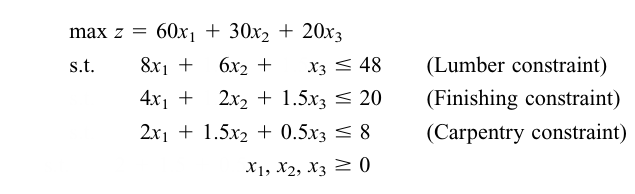
pg339

In [4]:
from scipy.optimize import linprog
c = [-60, -30,-20]
A = [[8, 6,1], 
     [4, 2,1.5],
     [2,1.5,0.5]]
b = [48,20,8]
bound = (0, None)
res = linprog(c, A_ub=A, b_ub=b, bounds=[bound, bound,bound], method='highs')

# print solution
print(f'Optimal solution: x1 = {res.x[0]:.2f}, x2 = {res.x[1]:.2f}, x3={res.x[2]:.2f}')
print(f'Maximum profit = $ {-res.fun:.2f}')

Optimal solution: x1 = 2.00, x2 = 0.00, x3=8.00
Maximum profit = $ 280.00


In [6]:
#solve usin gekko
m=GEKKO(remote=False)
x = m.Array(m.Var,3,lb=0)
m.Minimize(c@x)
Ax = A@x
m.Equations([Ax[i]<=b[i] for i in range(len(b))])
#m.options.SOLVER=1 #to make sure its integer
m.solve(disp=False)

# Print the results
print("Objective function: ", -m.options.objfcnval)# why does it keep on adding should i create new model again??: m=GEKKO(remote=False)
print("Optimal solution: ", x)


Objective function:  280.00000046
Optimal solution:  [[2.0000000186] [0.0] [7.9999999671]]


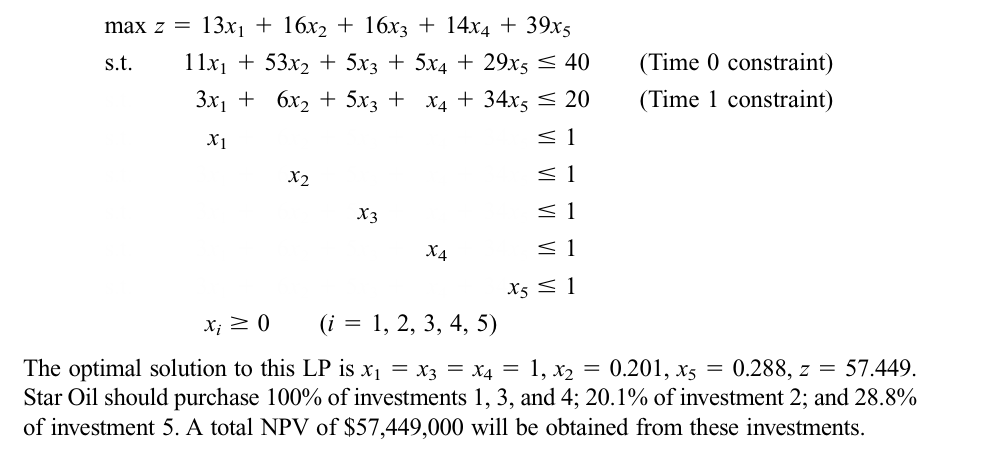

In [10]:
m = GEKKO(remote=False)
x = m.Array(m.Var,5,lb=0,ub=1)
C=[-13, -16,-16,-14,-39]
A=[[11,53,5,5,29],
   [3,6,5,1,34]]
b = [40,20]
m.Minimize(C@x)
Ax = A@x
m.Equations([Ax[i]<=b[i] for i in range(len(b))])
m.options.SOLVER=1 #to make sure its integer
m.solve(disp=False)

# Print the results
print("Objective function: ", -m.options.objfcnval)
print("Optimal solution: ", x)

Objective function:  57.449017199
Optimal solution:  [[1.0] [0.20085995086] [1.0] [1.0] [0.28808353808]]


Sailco Inventory pg117 and matrix generation pg181


In [13]:
#Sailco Inventory pg117 and matrix generation pg181
D=[40,60,75,25]
inv1=10 # must be more than zero

 # then i shall be len=5??
#xi= sailboats procuced during quarter i
#xi<=40 then cost= 400 else overtime cost=450
#h=20
t=4
# end of variables that could be parameters

m = GEKKO(remote=False)
x = m.Array(m.Var,t,lb=0,ub=40) # number of sailboats produced by regular-time labor (at $400/boat) during quarter t (t 1, 2, 3, 4)
y= m.Array(m.Var,t,lb=0) # number of sailboats produced by overtime labor (at $450/boat)during quarter t (t 1, 2, 3, 4)#

# i_t number of sailboats on hand at end of quarter t (t 1, 2, 3, 4)

#In formulating any multiperiod LP model,the hardest step is usually finding the relation (such as (61)) that relates decision variables from different periods.pg118
#inv=m.Intermediate(i_.append(i[(i-1)]+(x[i]+y[i]) - D[i] for i in range(len(D))))
inv=[None]*((t+1))
inv[0]=m.Intermediate(inv1)
for i in range(1,(len(D)+1)):
    inv[i]=m.Intermediate( (inv[(i-1)]+(x[(i-1)]+y[(i-1)]) - D[(i-1)] ) )
    m.Equations([inv[i]>=0])
#m.Equations([inv[i]>=0 for i in range(1,len(D))])
#m.Equations([inv[g]>=0[i] for g in range(len(inv))])
#m.Equations(inv=0)

m.Minimize(400*np.sum(x)+450*np.sum(y)+20*np.sum(inv[1:]))
m.options.SOLVER=1 
m.solve()
print("Objective function: ", m.options.objfcnval)
print("Optimal x solution: ", x)
print("Optimal y solution: ", y)
print("Optimal i solution: ", inv)

 ----------------------------------------------------------------
 APMonitor, Version 1.0.3
 APMonitor Optimization Suite
 ----------------------------------------------------------------
 
 
 --------- APM Model Size ------------
 Each time step contains
   Objects      :  0
   Constants    :  0
   Variables    :  12
   Intermediates:  5
   Connections  :  0
   Equations    :  10
   Residuals    :  5
 
 Number of state variables:    12
 Number of total equations: -  4
 Number of slack variables: -  4
 ---------------------------------------
 Degrees of freedom       :    4
 
 ----------------------------------------------
 Steady State Optimization with APOPT Solver
 ----------------------------------------------
 
 Iter    Objective  Convergence
    0  7.85563E+04  1.90000E+02
    1  7.84500E+04  1.76942E-16
    3  7.84500E+04  0.00000E+00
 Successful solution
 
 ---------------------------------------------------
 Solver         :  APOPT (v1.0)
 Solution time  :  0.04379999999999999

In [15]:
#Sailco Inventory pg117 and matrix generation pg181
D=m.Param([40,60,75,25])
inv0=10
Cost=400
overtime_cost=450
regualar_production=40
holding_cost=20
# parameters

m = GEKKO(remote=False)
x = m.Array(m.Var,len(D),lb=0,ub=regualar_production) 
y= m.Array(m.Var,len(D),lb=0) 

inv=[None]*((len(D)+1))
inv[0]=m.Intermediate(inv0)
for i in range(1,(len(D)+1)):
    inv[i]=m.Intermediate( (inv[(i-1)]+(x[(i-1)]+y[(i-1)]) - D[(i-1)] ) )
    m.Equations([inv[i]>=0])


m.Minimize(Cost*np.sum(x)+overtime_cost*np.sum(y)+holding_cost*np.sum(inv[1:]))
m.options.SOLVER=1 
m.solve()
print("Objective function: ", m.options.objfcnval)
print("Optimal x solution: ", x)
print("Optimal y solution: ", y)
print("Optimal i solution: ", inv)

 ----------------------------------------------------------------
 APMonitor, Version 1.0.3
 APMonitor Optimization Suite
 ----------------------------------------------------------------
 
 
 --------- APM Model Size ------------
 Each time step contains
   Objects      :  0
   Constants    :  0
   Variables    :  12
   Intermediates:  5
   Connections  :  0
   Equations    :  10
   Residuals    :  5
 
 Number of state variables:    12
 Number of total equations: -  4
 Number of slack variables: -  4
 ---------------------------------------
 Degrees of freedom       :    4
 
 ----------------------------------------------
 Steady State Optimization with APOPT Solver
 ----------------------------------------------
 
 Iter    Objective  Convergence
    0  7.85563E+04  1.90000E+02
    1  7.84500E+04  1.76942E-16
    3  7.84500E+04  0.00000E+00
 Successful solution
 
 ---------------------------------------------------
 Solver         :  APOPT (v1.0)
 Solution time  :  0.0611 sec
 Objecti

In [17]:
len(D)

4

In [19]:
#check page 57 doc
m = GEKKO(remote=False)
x = [None]*4
x[0]=m.Intermediate(0.5)
for i in range(1,4):
    x[i]=m.Intermediate(i)
    print(i)
    m.Equations([x[i]>=0])


1
2
3


In [21]:
D=[40,60,75,25]
inv0=10

 # then i shall be len=5??
#xi= sailboats procuced during quarter i
#xi<=40 then cost= 400 else overtime cost=450
#h=20
t=4
m = GEKKO(remote=False)
x = m.Array(m.Var,t,lb=0,ub=40) # number of sailboats produced by regular-time labor (at $400/boat) during quarter t (t 1, 2, 3, 4)
y= m.Array(m.Var,t,lb=0) # number of sailboats produced by overtime labor (at $450/boat)during quarter t (t 1, 2, 3, 4)#

# i_t number of sailboats on hand at end of quarter t (t 1, 2, 3, 4)

#In formulating any multiperiod LP model,the hardest step is usually finding the relation (such as (61)) that relates decision variables from different periods.pg118
inv1=m.Intermediate(inv0+(x[0]+y[0])-D[0])
inv2=m.Intermediate(inv1+(x[1]+y[1])-D[1])
inv3=m.Intermediate(inv2+(x[2]+y[2])-D[2])
inv4=m.Intermediate(inv3+(x[3]+y[3])-D[3])
#m.Equations([inv[i]>=0 for i in range(1,len(inv)) ])
m.Equations([inv1>=0,inv2>=0,inv3>=0,inv4>=0])


m.Minimize(400*np.sum(x)+450*np.sum(y)+20*np.sum([inv1,inv2,inv3,inv4]))
m.options.SOLVER=1 
m.solve(disp=False)
print("Objective function: ", m.options.objfcnval)
print("Optimal x solution : ", x)
print("Optimal y solution: ", y)
print("Optimal i solution: ", inv1,inv2,inv3,inv4)

Objective function:  78450.0
Optimal x solution :  [[40.0] [40.0] [40.0] [25.0]]
Optimal y solution:  [[0.0] [10.0] [35.0] [0.0]]
Optimal i solution:  i14 i15 i16 i17


A Work-Scheduling Problem pg88,125

In [118]:
m = GEKKO(remote=False)
D=[17,13,15,19,14,16,11]
wdays=5
h=len(D)-wdays
#x_i number of employees beginning work on day i
x = m.Array(m.Var,len(D),lb=0)
x[2:]

array([0, 0, 0, 0, 0], dtype=object)

In [134]:
#the template staff
D=[1,2,3,4,5,6,7]
wdays=5
h=len(D)-wdays
i=1
while len(D[(i+h):])>=1:
    print(i,D[:i],D[(i+h):])
    i+=1
print("then i= ", i)
while i <=len(D):
    print(i,D[(i-wdays):i])
    i+=1
np.sum(D)

1 [1] [4, 5, 6, 7]
2 [1, 2] [5, 6, 7]
3 [1, 2, 3] [6, 7]
4 [1, 2, 3, 4] [7]
then i=  5
5 [1, 2, 3, 4, 5]
6 [2, 3, 4, 5, 6]
7 [3, 4, 5, 6, 7]


np.int64(28)

In [357]:
D=[17,13,15,19,14,16,11]
wdays=5 # must be below len(D)
h=len(D)-wdays #holidays

m = GEKKO(remote=False)
x = m.Array(m.Var,len(D),lb=0,integer=True)
C=np.ones(len(D))

#generate matrix A
Raws=[None]*len(D) #elements shall be raws
i=1
while len(D[(i+h):])>=1:
    Raws1=np.zeros(len(D))
    Raws1[:i]=1
    Raws1[(i+h):]=1
    Raws[(i-1)]=Raws1
    #print(Raws)
    i+=1

while i <=len(D):
    Raws1=np.zeros(len(D))
    Raws1[(i-wdays):i]=1
    Raws[(i-1)]=Raws1
    i+=1
    
A=np.array(Raws) # bravo finished creating A
b=np.array(D)

m.Minimize(C@x)
Ax = A@x
m.Equations([Ax[i]>=b[i] for i in range(len(b))])

m.options.SOLVER=1 #to make sure its integer
m.solve(disp=False)

# Print the results
print("Objective function: ", m.options.objfcnval)
print("Optimal solution: ", x)
print("then A is ")
print(A)
print("check if this problem may have multiple solutions pg 90 ???")

Objective function:  23.0
Optimal solution:  [[5.0] [4.0] [2.0] [7.0] [0.0] [3.0] [2.0]]
then A is 
[[1. 0. 0. 1. 1. 1. 1.]
 [1. 1. 0. 0. 1. 1. 1.]
 [1. 1. 1. 0. 0. 1. 1.]
 [1. 1. 1. 1. 0. 0. 1.]
 [1. 1. 1. 1. 1. 0. 0.]
 [0. 1. 1. 1. 1. 1. 0.]
 [0. 0. 1. 1. 1. 1. 1.]]
check if this problem may have multiple solutions pg 90 ???


In [359]:
m = GEKKO(remote=False)
x = m.Array(m.Var,5,lb=0,ub=1)
C=np.array([-13, -16,-16,-14,-39])
A=np.array([[11,53,5,5,29],
   [3,6,5,1,34]])
b = np.array([40,20])
m.Minimize(C@x)
Ax = A@x
m.Equations([Ax[i]<=b[i] for i in range(len(b))])
m.options.SOLVER=1 #to make sure its integer
m.solve(disp=False)

# Print the results
print("Objective function: ", -m.options.objfcnval)
print("Optimal solution: ", x)

Objective function:  57.449017199
Optimal solution:  [[1.0] [0.20085995086] [1.0] [1.0] [0.28808353808]]


In [216]:
a2 = np.zeros(len(D))
a21=[a2,a2]
print(a21)
a22=np.array([a21])
a22

[array([0., 0., 0., 0., 0., 0., 0.]), array([0., 0., 0., 0., 0., 0., 0.])]


array([[[0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0.]]])

In [192]:
Raws=np.zeros(len(D))
Raws[3:]=1
Raws

array([0., 0., 0., 1., 1., 1., 1.])

In [361]:
m.cleanup()